In [11]:
#Khai báo các thư viện/hàm cần dùng
import sys
sys.path.append("..") #add thư mục gốc vào path để import các module con để chạy đc src bên dưới nè

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import classification_report

from src.models.complex_cnn import build_model
from src.data.preprocess import preprocess_image

In [12]:
#Đọc và chuẩn bị dữ liệu
train_df = pd.read_csv("../data/train_split.csv")
val_df = pd.read_csv("../data/validation_split.csv")
test_df = pd.read_csv("../data/test_split.csv")

train_paths = ("../data/" + train_df["file_name"]).to_numpy()
val_paths = ("../data/" + val_df["file_name"]).to_numpy()
test_paths = ("../data/" + test_df["file_name"]).to_numpy()

y_train = train_df["label"].to_numpy(dtype="float32")
y_val = val_df["label"].to_numpy(dtype="float32")
y_test = test_df["label"].to_numpy(dtype="float32")


def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (160, 160))
    image = image / 255.0
    return image, label


batch_size = 16

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, y_train))
train_ds = train_ds.shuffle(1000)
train_ds = train_ds.map(load_image, num_parallel_calls=2)
train_ds = train_ds.batch(batch_size).prefetch(1)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, y_val))
val_ds = val_ds.map(load_image, num_parallel_calls=2)
val_ds = val_ds.batch(batch_size).prefetch(1)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, y_test))
test_ds = test_ds.map(load_image, num_parallel_calls=2)
test_ds = test_ds.batch(batch_size).prefetch(1)

In [13]:
#Xây dựng model
model = build_model()
model.summary()

Model: "Complex_CNN_4_Blocks"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 160, 160,  │        432 │ input_layer_2[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │         64 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 160, 160,  │      2,304 │ re_lu_18[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │         64 │ conv2d_25[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 160, 160,  │      2,304 │ re_lu_19[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │         64 │ conv2d_26[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │ re_lu_18[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 160, 160,  │          0 │ add_8[0][0]       │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 80, 80,    │      4,608 │ re_lu_20[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        128 │ conv2d_27[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 80, 80,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 80, 80,    │      9,216 │ re_lu_21[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 80, 80,    │        512 │ re_lu_20[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        128 │ conv2d_28[0][0] 

 Total params: 317,297 (1.21 MB)

 Trainable params: 315,857 (1.20 MB)

 Non-trainable params: 1,440 (5.62 KB)

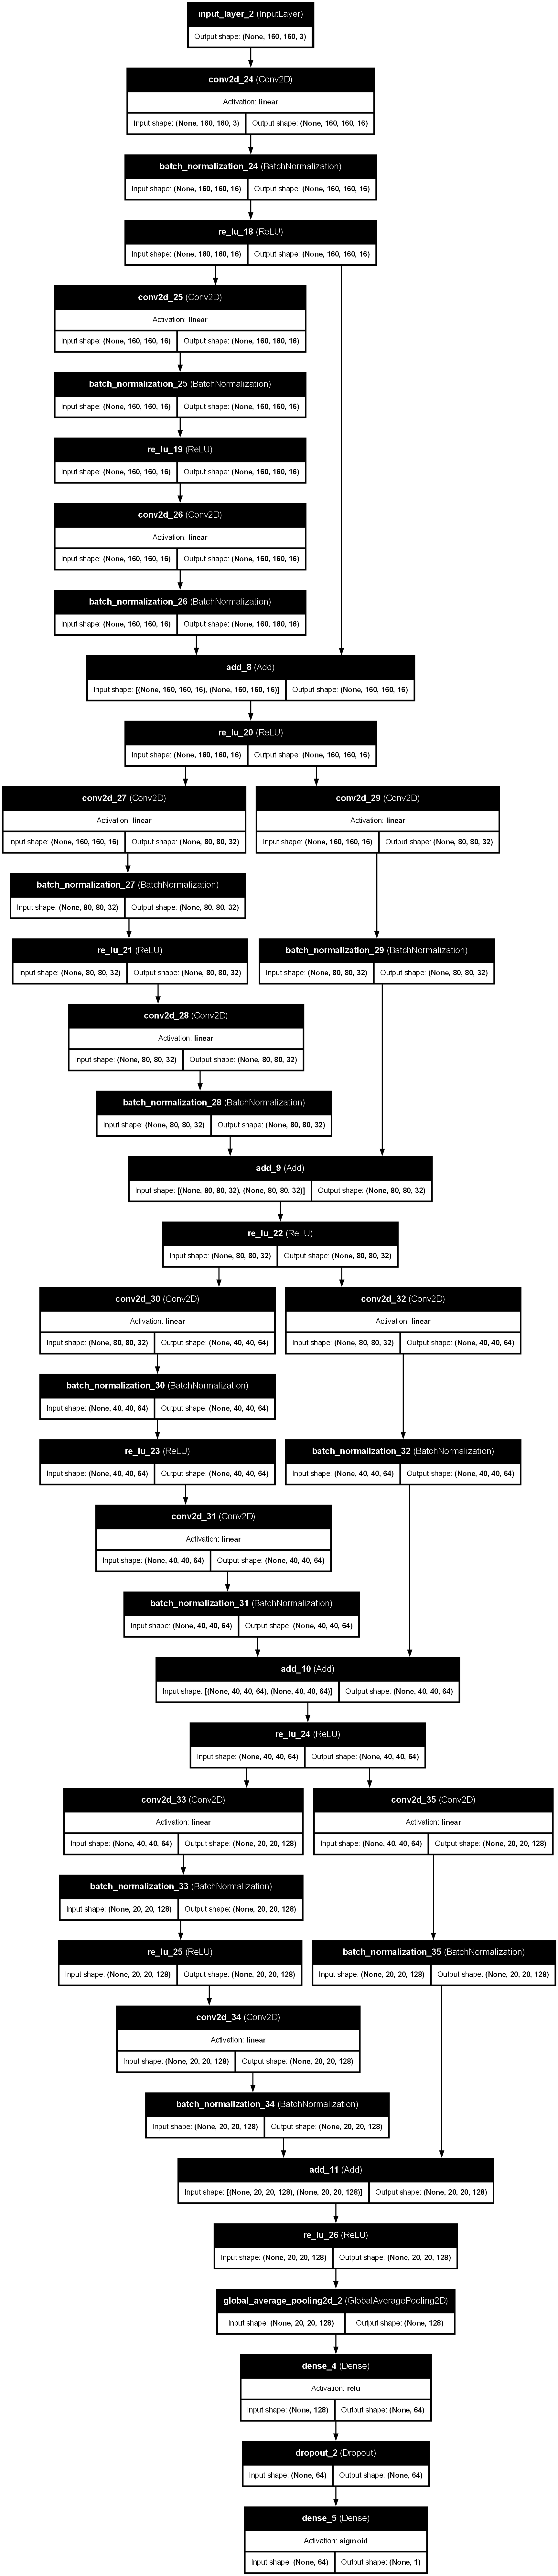

In [14]:
#Vẽ kiến trúc Complex CNN
tf.keras.utils.plot_model(model, to_file="../results/figures/complex_cnn_architecture.png", show_shapes=True, show_layer_names=True, show_layer_activations=True, dpi=120)

In [15]:
#Training model
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)
history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])

Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 411s 927ms/step - accuracy: 0.8490 - auc: 0.9209 - loss: 0.3621 - val_accuracy: 0.6693 - val_auc: 0.9278 - val_loss: 0.6348
Epoch 2/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 407s 929ms/step - accuracy: 0.8849 - auc: 0.9503 - loss: 0.2870 - val_accuracy: 0.9087 - val_auc: 0.9691 - val_loss: 0.2312
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 272s 622ms/step - accuracy: 0.8949 - auc: 0.9566 - loss: 0.2674 - val_accuracy: 0.9087 - val_auc: 0.9717 - val_loss: 0.2286
Epoch 4/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 273s 623ms/step - accuracy: 0.9000 - auc: 0.9601 - loss: 0.2562 - val_accuracy: 0.9273 - val_auc: 0.9798 - val_loss: 0.1895
Epoch 5/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 276s 631ms/step - accuracy: 0.8997 - auc: 0.9644 - loss: 0.2428 - val_accuracy: 0.9267 - val_auc: 0.9776 - val_loss: 0.1985
Epoch 6/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 266s 608ms/step - accuracy: 0.9176 - auc: 0.9692 - loss: 0.2242 - val_accuracy: 0.9293 - val_auc: 0.9812 - val_loss: 0.1868
Epoch 7/10
438/4

In [16]:
#Lưu model
model.save("../src/models/complex_cnn.keras")

In [17]:
# Đánh giá model trên tập test
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)

In [18]:
# Dự đoán nhãn trên tập test
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

94/94 ━━━━━━━━━━━━━━━━━━━━ 49s 519ms/step


In [19]:
# Tính các chỉ số đánh giá
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Accuracy: 0.9413
Precision: 0.9522
Recall: 0.9293
F1-score: 0.9406


In [20]:
# Báo cáo phân loại
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

         0.0       0.93      0.95      0.94       750
         1.0       0.95      0.93      0.94       750

    accuracy                           0.94      1500
   macro avg       0.94      0.94      0.94      1500
weighted avg       0.94      0.94      0.94      1500

